### Imports

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Load Dataset

##### option 1

In [ ]:
titanic_dataset = sns.load_dataset('titanic')
titanic_dataset.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


#### option 2

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train (1).csv


In [ ]:
titanic_dataset = pd.read_csv('train (1).csv')
titanic_dataset.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Dataset Explanation

Titanic was a British passenger liner, operated by the White Star Line, which sank in the North Atlantic Ocean on 15 April 1912 after striking an iceberg during her maiden voyage from Southampton, England, to New York City, United States. Of the estimated 2,224 passengers and crew aboard, more than 1,500 died, making it the deadliest sinking of a single ship up to that time. It remains the deadliest peacetime sinking of an ocean liner or cruise ship.

- PassengerId is the unique id of the row and it doesn't have any effect on target

- Survived is the target variable we are trying to predict (0 or 1):

    1 = Survived

    0 = Not Survived

- Pclass (Passenger Class) is the socio-economic status of the passenger and it is a categorical ordinal feature which has 3 unique values (1, 2 or 3):

    1 = Upper Class

    2 = Middle Class

    3 = Lower Class

- Name, Sex and Age are self-explanatory

- SibSp is the total number of the passengers' siblings and spouse

- Parch is the total number of the passengers' parents and children

- Ticket is the ticket number of the passenger

- Fare is the passenger fare

- Cabin is the cabin number of the passenger

- Embarked is port of embarkation and it is a categorical feature which has 3 unique values (C, Q or S):

    C = Cherbourg

    Q = Queenstown

    S = Southampton

### Basic Dataset Info

In [ ]:
titanic_dataset.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
titanic_dataset.shape

(891, 12)

In [ ]:
titanic_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
titanic_dataset.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
print("\nData types & non-null counts:")
titanic_dataset.info()


Data types & non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
missing = titanic_dataset.isnull().sum()
print("\nMissing values:")
print(missing)


Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


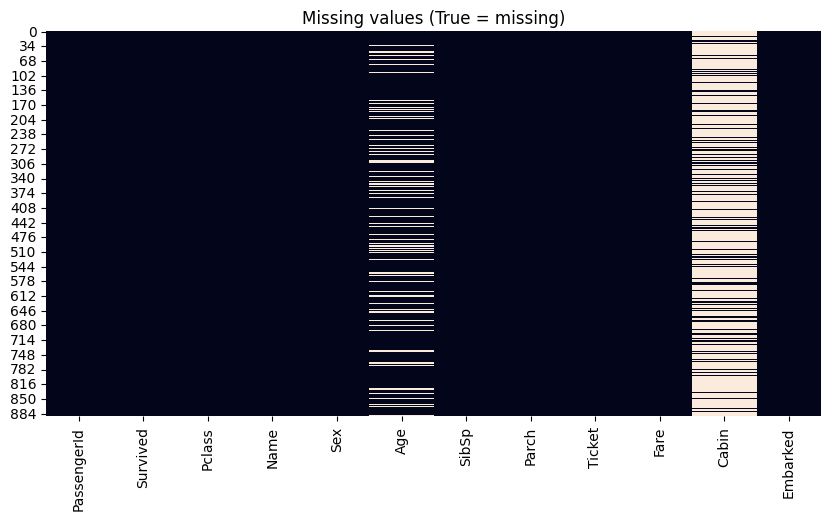

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(titanic_dataset.isnull(), cbar=False) # cbar=False removes the color scale bar on the side to keep the plot cleaner.
plt.title("Missing values (True = missing)")
plt.show()

In [ ]:
# Numerical columns
num_cols = titanic_dataset.select_dtypes(include=['int64', 'float64']).columns
print("Numerical Columns:", list(num_cols))

# Categorical columns
cat_cols = titanic_dataset.select_dtypes(include=['object', 'category']).columns
print("Categorical Columns:", list(cat_cols))


Numerical Columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical Columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [ ]:
titanic_dataset.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
for col in titanic_dataset.columns:
    print(col, ":", titanic_dataset[col].nunique(), "unique values")
    if titanic_dataset[col].nunique() < 10:
        print(titanic_dataset[col].unique())

PassengerId : 891 unique values
Survived : 2 unique values
[0 1]
Pclass : 3 unique values
[3 1 2]
Name : 891 unique values
Sex : 2 unique values
['male' 'female']
Age : 88 unique values
SibSp : 7 unique values
[1 0 3 4 2 5 8]
Parch : 7 unique values
[0 1 2 5 3 4 6]
Ticket : 681 unique values
Fare : 248 unique values
Cabin : 147 unique values
Embarked : 3 unique values
['S' 'C' 'Q' nan]


### Analyzing Missing Values

Missing-value strategies (short guide):

Numerical

Median — use for skewed data or when outliers exist (e.g., Age or Fare skewed → median recommended).

Mean — fine if distribution roughly symmetric.

Group-based imputation — if Age depends on Sex & Class, fill Age with median within (Sex, Pclass) groups (more accurate).

Model-based / KNN / IterativeImputer — for advanced use when relationships are complex.

Interpolation/forward-fill — for time series.

Drop rows — only if that row set is small and missingness is random.

Categorical

Mode — simple and common if only a few missing.

'Missing' label — if missingness might carry meaning (e.g., Cabin missing).

Predictive imputation — predict category using other features (advanced).

High missingness (>40–50%): think twice — drop or engineer new features (e.g., extract deck from Cabin and set others to 'Unknown').

Create missing indicators (e.g., Age_missing) — this lets models learn whether missingness itself is informative.

Feature engineering:

FamilySize = SibSp + Parch + 1 often helps capture family effects.

IsAlone (FamilySize == 1) is handy.

Extracting Title from Name (Mr/Mrs/Miss/Master) often captures social status and is predictive.

When to drop a column: drop when >50% missing and you cannot reliably impute (but first consider extracting partial information — e.g., deck letter from Cabin).

Age         177
Cabin       687
Embarked      2
dtype: int64


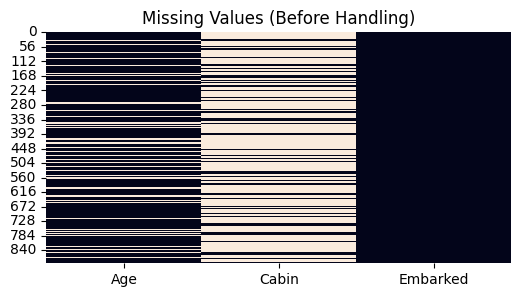

In [ ]:
# Missing values before handling
print(titanic_dataset[['Age','Cabin','Embarked']].isnull().sum())

# Visualize missing values
plt.figure(figsize=(6,3))
sns.heatmap(titanic_dataset[['Age','Cabin','Embarked']].isnull(), cbar=False)
plt.title("Missing Values (Before Handling)")
plt.show()

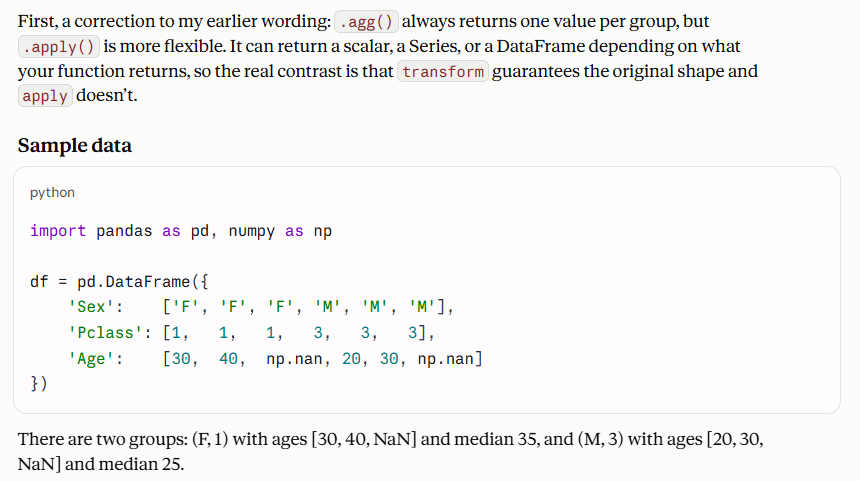

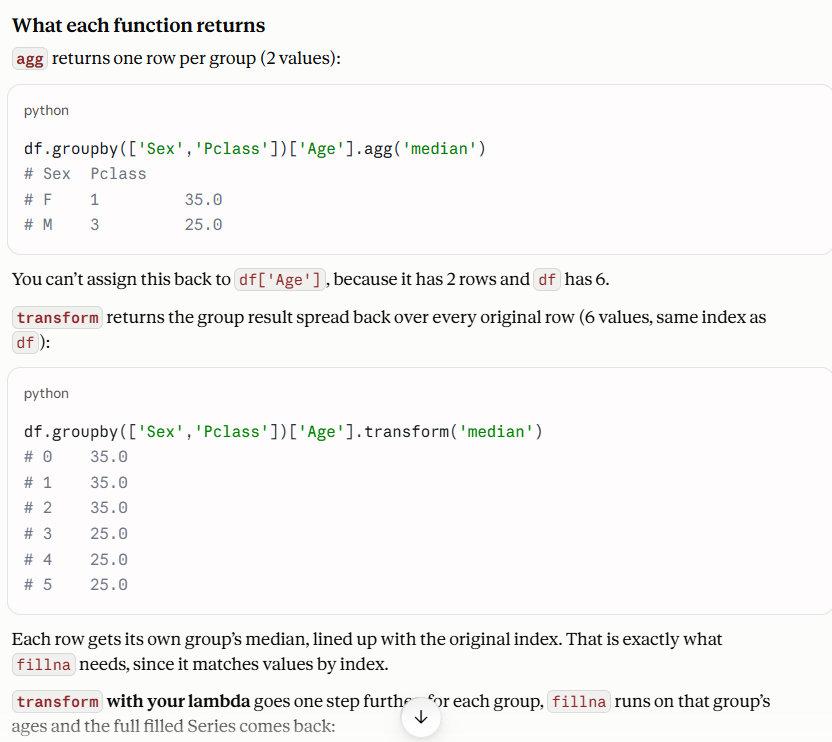

### Explore Distributions (Before Handling)

Age (Numerical)

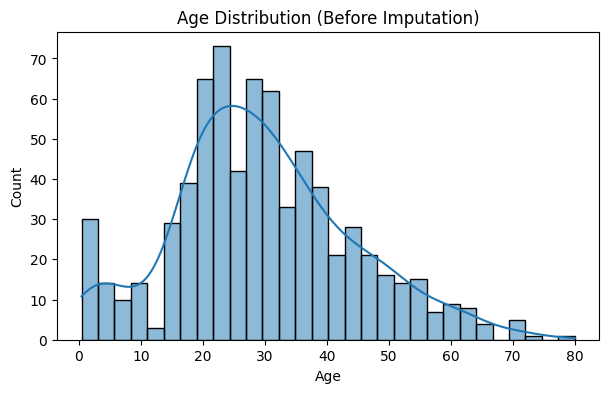

Skewness of Age: 0.38910778230082704


In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(titanic_dataset['Age'],bins=30, kde=True) # kde=True adds a smooth curve (Kernel Density Estimate) to show the data distribution shape.
plt.title("Age Distribution (Before Imputation)")
plt.show()

print("Skewness of Age:", titanic_dataset['Age'].skew())


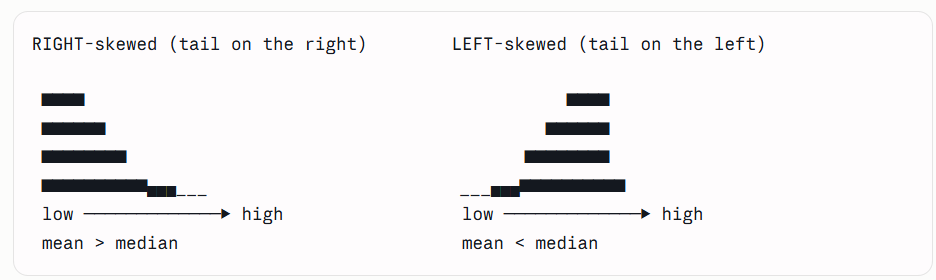

If skewness ≈ 0 → distribution is normal → use mean.

If skewed (Age is usually slightly left-skewed) → use median.

In Titanic: use group median (Sex + Pclass) for better accuracy.

Embarked (Categorical)

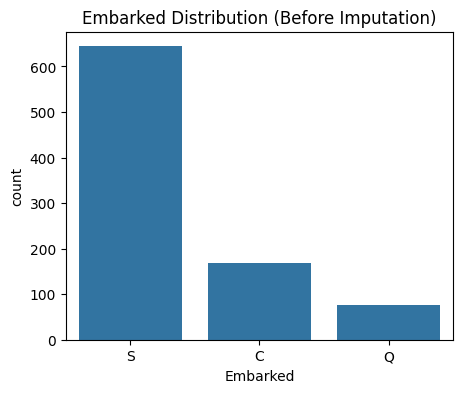

In [ ]:
plt.figure(figsize=(5,4))
sns.countplot(x='Embarked', data=titanic_dataset)
plt.title("Embarked Distribution (Before Imputation)")
plt.show()


If only a few missing → fill with mode (most frequent value)

Cabin (Categorical with Many Missing)

In [ ]:
titanic_dataset['Cabin'].head()

,Cabin
0,NaN
1,C85
2,NaN
3,C123
4,NaN


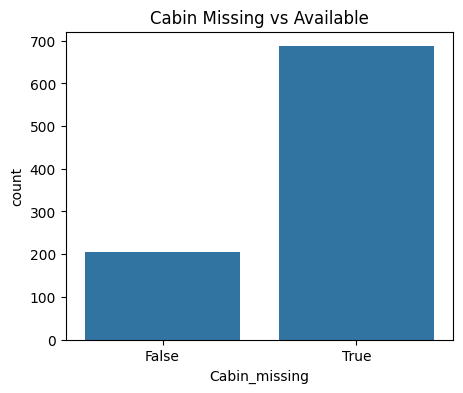

In [ ]:
plt.figure(figsize=(5,4))
titanic_dataset['Cabin_missing'] = titanic_dataset['Cabin'].isnull()
sns.countplot(x='Cabin_missing', data=titanic_dataset)
plt.title("Cabin Missing vs Available")
plt.show()


In [ ]:
titanic_dataset['Cabin_missing'].head()

,Cabin_missing
0,True
1,False
2,True
3,False
4,True


Too many missing (~77%).

Dropping column would lose info.

Better technique: extract Deck (first letter like A,B,C…) and set missing as "Unknown".

## Handling Missing Values

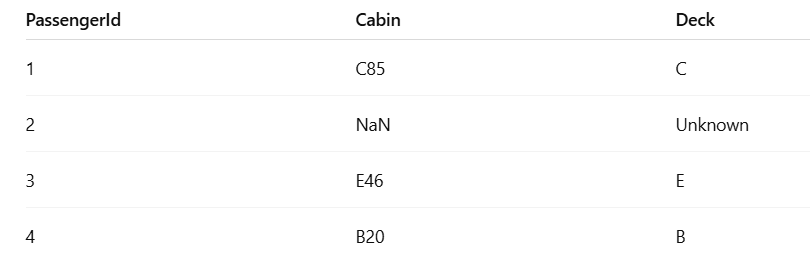

lambda function

A one-line, anonymous function (no need to def it).

lambda arguments: expression

lambda x: x.fillna(x.median())

For each group (like "Female, Pclass 1"), it takes the Age values (x).

Fills missing values (NaN) with that group’s median.

In [ ]:
# Age → fill with group median (correct way)
titanic_dataset['Age'] = titanic_dataset.groupby(['Sex','Pclass'])['Age'].transform(lambda x: x.fillna(x.median())) # transform ensures the output has the same length and order as the original column (so you can directly assign it back).

# Embarked → fill with mode
titanic_dataset['Embarked'].fillna(titanic_dataset['Embarked'].mode()[0], inplace=True)

# Cabin → extract Deck
titanic_dataset['Deck'] = titanic_dataset['Cabin'].apply(lambda x: x[0] if pd.notnull(x) else 'Unknown')


/tmp/ipython-input-191299449.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic_dataset['Embarked'].fillna(titanic_dataset['Embarked'].mode()[0], inplace=True)


In [ ]:
titanic_dataset.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Cabin_missing,Deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,True,Unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,True,Unknown
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False,C
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,True,Unknown


In [ ]:
missing = titanic_dataset.isnull().sum()
print("\nMissing values:")
print(missing)


Missing values:
PassengerId        0
Survived           0
Pclass             0
Name               0
Sex                0
Age                0
SibSp              0
Parch              0
Ticket             0
Fare               0
Cabin            687
Embarked           0
Cabin_missing      0
Deck               0
dtype: int64


### Anaylsis After Handling Missing Values

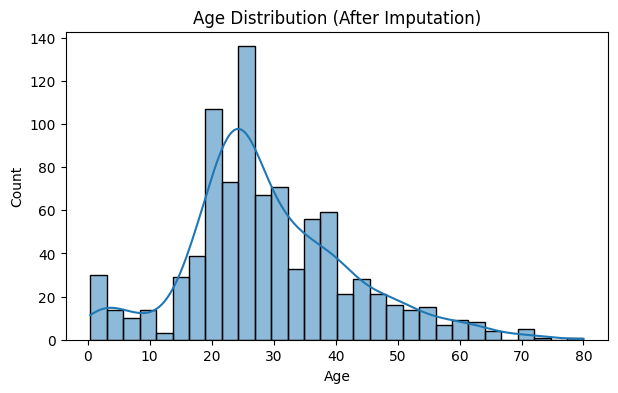

Skewness of Age: 0.5340834483875482


In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(titanic_dataset['Age'],bins=30, kde=True)
plt.title("Age Distribution (After Imputation)")
plt.show()

print("Skewness of Age:", titanic_dataset['Age'].skew())


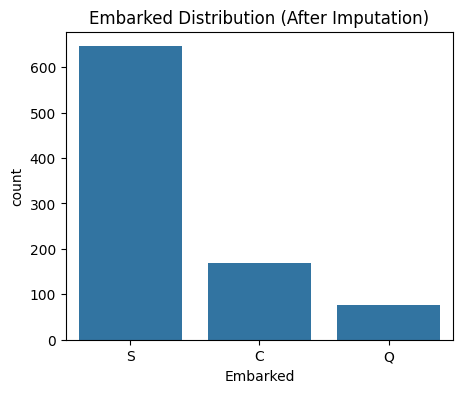

In [ ]:
plt.figure(figsize=(5,4))
sns.countplot(x='Embarked', data=titanic_dataset)
plt.title("Embarked Distribution (After Imputation)")
plt.show()


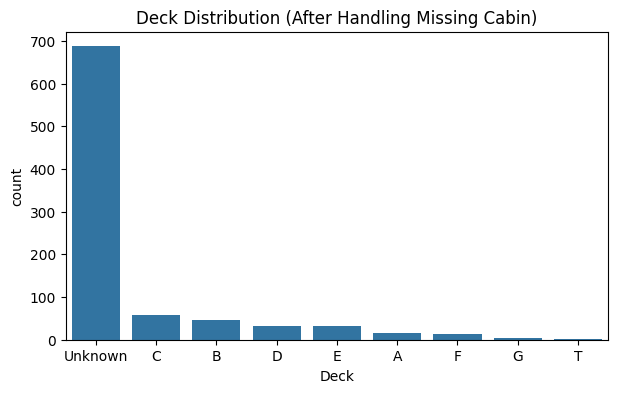

In [ ]:
plt.figure(figsize=(7,4))
sns.countplot(x='Deck', data=titanic_dataset, order=titanic_dataset['Deck'].value_counts().index)
plt.title("Deck Distribution (After Handling Missing Cabin)")
plt.show()


### Feature engineering

In [ ]:
#Family size & is alone
if set(['SibSp','Parch']).issubset(titanic_dataset.columns):
    titanic_dataset['FamilySize'] = titanic_dataset['SibSp'] + titanic_dataset['Parch'] + 1
    # if titanic_dataset['FamilySize'] == 1:
    #     titanic_dataset['IsAlone'] = 1
    # else:
    #     titanic_dataset['IsAlone'] = 0
    titanic_dataset['IsAlone'] = (titanic_dataset['FamilySize'] == 1).astype(int)
    # 1 means alone
    # 0 means with family members

In [ ]:
titanic_dataset.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Cabin_missing,Deck,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,True,Unknown,2,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False,C,2,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,True,Unknown,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False,C,2,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,True,Unknown,1,1


Regex explained: r',\s*([^\.]+)\.'

, → look for a comma (names are written as "LastName, Title. FirstName").

\s* → match any spaces after the comma.

([^\.]+) →

(...) = capturing group (the part we want to extract).

[^\.]+ = one or more characters that are not a dot (.) → this gives us Mr, Mrs, Miss, etc.

\. → literal dot after the title.



"Braund, Mr. Owen Harris" → regex finds Mr

"Cumings, Mrs. John Bradley" → regex finds Mrs

"Heikkinen, Miss. Laina" → regex finds Miss

In [ ]:
# Extract Title from Name (if present) — helps capture social status
if 'Name' in titanic_dataset.columns:
    titanic_dataset['Title'] = titanic_dataset['Name'].str.extract(r',\s*([^\.]+)\.')[0].str.strip()
    common_titles = ['Mr','Mrs','Miss','Master']
    titanic_dataset['Title'] = titanic_dataset['Title'].apply(lambda t: t if t in common_titles else 'Rare')

titanic_dataset.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Cabin_missing,Deck,FamilySize,IsAlone,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,True,Unknown,2,0,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False,C,2,0,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,True,Unknown,1,1,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False,C,2,0,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,True,Unknown,1,1,Mr


### Visual EDA

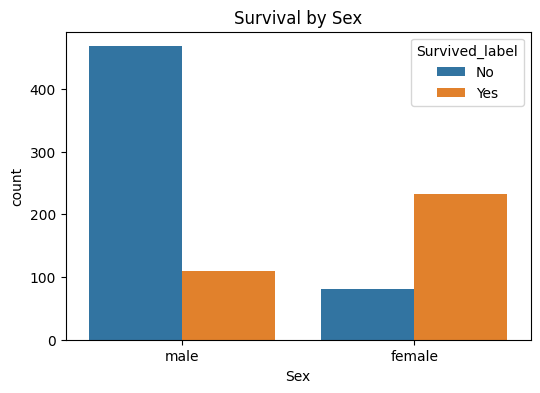

In [ ]:
# (A) Survival counts by Sex
if set(['Sex','Survived']).issubset(titanic_dataset.columns):
    titanic_dataset['Survived_label'] = titanic_dataset['Survived'].map({0:'No', 1:'Yes'})
    plt.figure(figsize=(6,4))
    sns.countplot(x='Sex', hue='Survived_label', data=titanic_dataset)
    plt.title('Survival by Sex')
    plt.show()


/tmp/ipython-input-1495255943.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=titanic_dataset, estimator=np.mean, ci=None)


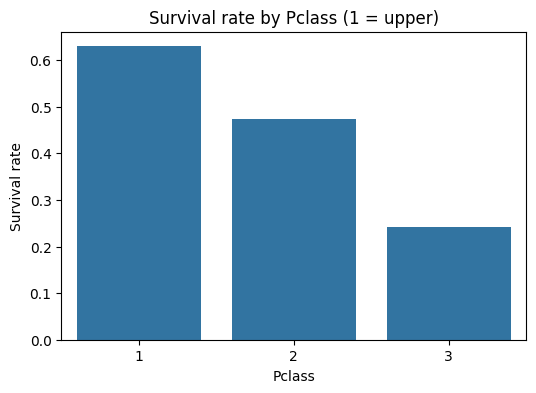

In [ ]:
# (B) Survival rate by Pclass
if set(['Pclass','Survived']).issubset(titanic_dataset.columns):
    plt.figure(figsize=(6,4))
    sns.barplot(x='Pclass', y='Survived', data=titanic_dataset, estimator=np.mean, ci=None)
    plt.title('Survival rate by Pclass (1 = upper)')
    plt.ylabel('Survival rate')
    plt.show()

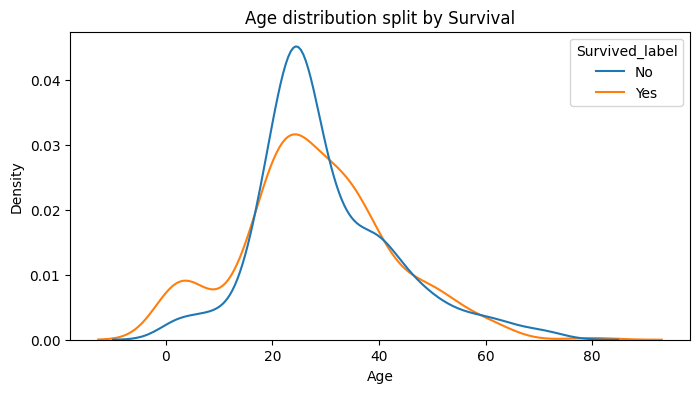

In [ ]:
# (C) Age distribution by survival
if 'Age' in titanic_dataset.columns:
    plt.figure(figsize=(8,4))
    sns.kdeplot(data=titanic_dataset, x='Age', hue='Survived_label', common_norm=False)
    plt.title('Age distribution split by Survival')
    plt.show()

/tmp/ipython-input-2761165346.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Embarked', y='Survived', data=titanic_dataset, estimator=np.mean, ci=None)


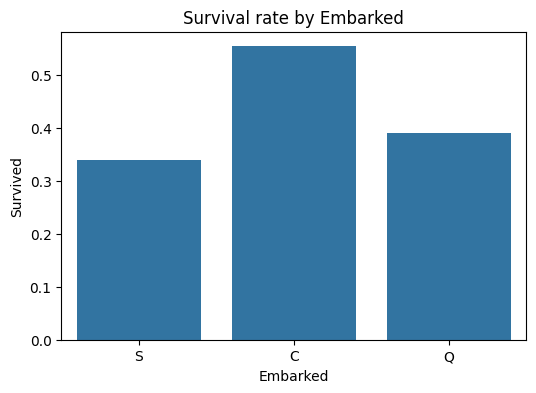

In [ ]:
# (F) Survival rate by Embarked
if set(['Embarked','Survived']).issubset(titanic_dataset.columns):
    plt.figure(figsize=(6,4))
    sns.barplot(x='Embarked', y='Survived', data=titanic_dataset, estimator=np.mean, ci=None)
    plt.title('Survival rate by Embarked')
    plt.show()

Colors:

Red (close to +1) → strong positive relation.

Blue (close to -1) → strong negative relation.

Near 0 → weak/no relation.

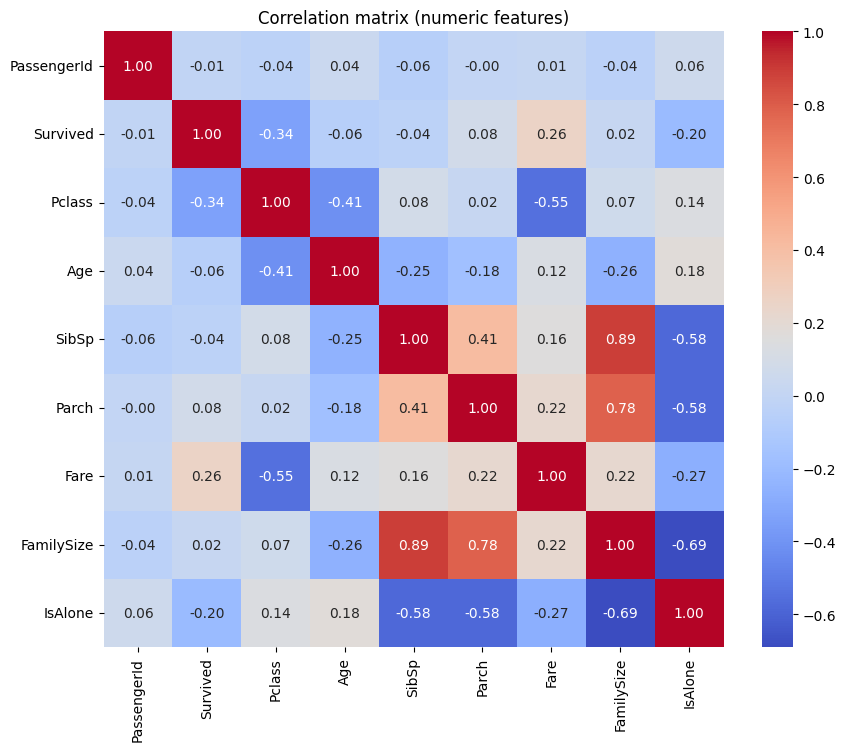

In [ ]:
# (F) Correlation heatmap (numeric features)
num_cols = titanic_dataset.select_dtypes(include=[np.number]).columns.tolist()
plt.figure(figsize=(10,8))
sns.heatmap(titanic_dataset[num_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation matrix (numeric features)')
plt.show()

### Analysis questions

How does survival differ between males and females?

How does passenger class (Pclass) affect survival?

Does age (children vs adults vs seniors) affect survival probability?

Is Fare (a proxy for wealth/class) associated with higher survival?

Does family size (alone vs small family vs large family) influence survival?

In [ ]:
# Q1: Does sex affect survival?
if 'Sex' in titanic_dataset.columns:
    survival_by_sex = titanic_dataset.groupby('Sex')['Survived'].mean().sort_values(ascending=False)
    print("Q1 - Survival rate by Sex:\n", survival_by_sex)

Q1 - Survival rate by Sex:
 Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


In [ ]:
# Q2: How does passenger class affect survival?
if 'Pclass' in titanic_dataset.columns:
    survival_by_class = titanic_dataset.groupby('Pclass')['Survived'].mean().sort_values(ascending=False)
    print("\nQ2 - Survival rate by Pclass:\n", survival_by_class)


Q2 - Survival rate by Pclass:
 Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


right=True (default): 12 falls in Child, because the first bracket is (0, 12]


right=False (your code): 12 falls in Teen, because the second bracket is [12, 18)

In [ ]:
# Q3: How does age affect survival? (binned)
if 'Age' in titanic_dataset.columns:
    bins = [0, 12, 18, 35, 60, 120]
    labels = ['Child','Teen','YoungAdult','Adult','Senior']
    titanic_dataset['AgeGroup'] = pd.cut(titanic_dataset['Age'], bins=bins, labels=labels, right=False)
    print("\nQ3 - Survival rate by AgeGroup:\n", titanic_dataset.groupby('AgeGroup')['Survived'].mean())


Q3 - Survival rate by AgeGroup:
 AgeGroup
Child         0.573529
Teen          0.488889
YoungAdult    0.337232
Adult         0.422594
Senior        0.269231
Name: Survived, dtype: float64


/tmp/ipython-input-1909243456.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("\nQ3 - Survival rate by AgeGroup:\n", titanic_dataset.groupby('AgeGroup')['Survived'].mean())


In [ ]:
# Q5: Does family size or being alone affect survival?
if 'FamilySize' in titanic_dataset.columns:
    print("\nQ5 - Survival rate by FamilySize (small sample):")
    display(titanic_dataset.groupby('FamilySize')['Survived'].mean().sort_index())
    print("\nSurvival rate when IsAlone = 1 vs 0:")
    display(titanic_dataset.groupby('IsAlone')['Survived'].mean())


Q5 - Survival rate by FamilySize (small sample):


,Survived
FamilySize,
1,0.303538
2,0.552795
3,0.578431
4,0.724138
5,0.200000
6,0.136364
7,0.333333
8,0.000000
11,0.000000



Survival rate when IsAlone = 1 vs 0:


,Survived
IsAlone,
0,0.505650
1,0.303538


In [ ]:
# Save cleaned dataset for later use (optional)
titanic_dataset.to_csv('titanic_cleaned_for_eda.csv', index=False)
print("Cleaned dataset saved as titanic_cleaned_for_eda.csv")

Cleaned dataset saved as titanic_cleaned_for_eda.csv


### Conclusion

“From the plots and groupby numbers we can see female passengers had a much higher survival rate than males.”

“First-class passengers had higher survival rates than second and third class, suggesting socio-economic status mattered.”

“Younger passengers (children) show different survival patterns — they were often prioritized.”

“Higher Fare tends to be associated with higher survival (fare is a proxy for class/wealth).”

“Family size effect is nuanced: very large families had lower survival (harder to coordinate), while small families or those alone sometimes had different outcomes — check the FamilySize plot to interpret.”

# Hypothesis Testing

Scenario:

The company claims that the average passenger age on the Titanic was 30 years.
We want to test if the actual sample mean (from our dataset) is different from 30.

Step 1: Set up Hypotheses

H₀: μ = 30 (Population mean is 30)

H₁: μ ≠ 30 (Population mean is not 30)
Step 2: Conditions for Z-Test

✅ Large sample (n > 30)
✅ Population std. deviation unknown → we’ll estimate using sample std. (since Titanic has 700+ rows)

So, Z-test is fine to approximate.

In [ ]:
from scipy import stats
import numpy as np
import pandas as pd
df1 = pd.read_csv('titanic_cleaned_for_eda.csv')
df1.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Cabin_missing,Deck,FamilySize,IsAlone,Title,Survived_label,AgeGroup
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,True,Unknown,2,0,Mr,No,YoungAdult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,False,C,2,0,Mrs,Yes,Adult
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,True,Unknown,1,1,Miss,Yes,YoungAdult
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,False,C,2,0,Mrs,Yes,Adult
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,True,Unknown,1,1,Mr,No,Adult


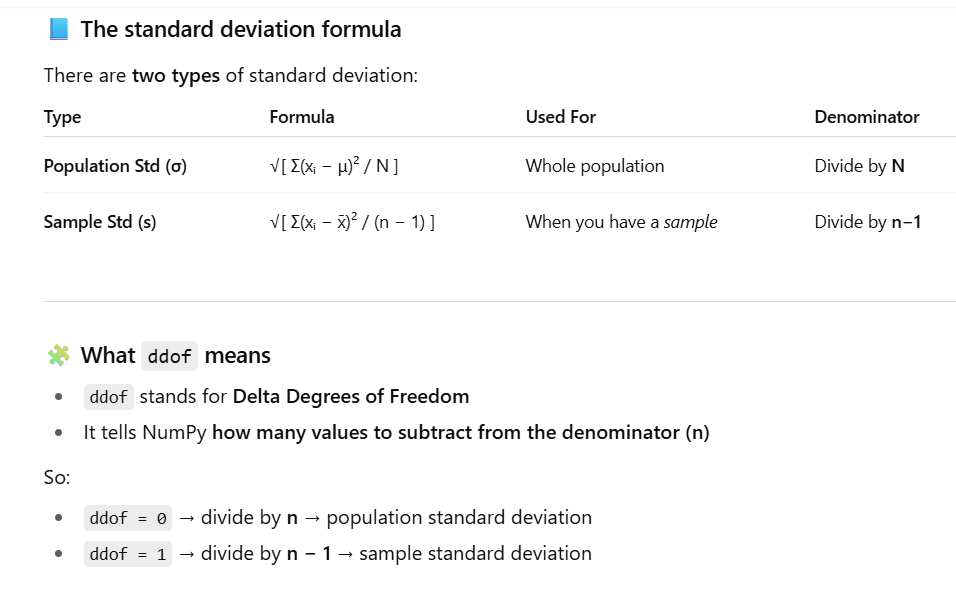

In [ ]:

# step 02 - Table
alpha = 0.05 # 5%
z_critical = stats.norm.ppf(1 - alpha/2) # two tail test, ppf -> Percent point function, gives you the z test value
# z_critical_right = stats.norm.ppf(1 - alpha)   # right tail
# z_critical_left = stats.norm.ppf(alpha)        # left tail


# step 3 - Test Value
ages = df1['Age']
population_mean = 30
sample_mean = np.mean(ages)
sample_std = np.std(ages, ddof=1) # ddof = 1 means sample std, if 0, then means population std
n = len(ages)
z = (sample_mean - population_mean) / (sample_std / np.sqrt(n)) # calculated z-value


print(f"Sample mean: {sample_mean:.2f}")
print(f"Z-statistic: {z:.3f}")
print(f"Z- critical: {z_critical:.4f}")

if abs(z) > abs(z_critical):
    print("Reject H₀")
else:
    print("Fail to reject H₀")

Sample mean: 29.11
Z-statistic: -1.991
Z- critical: 1.9600
Reject H₀


Step 4: Interpretation
Value	Meaning
Z-statistic:	How many standard deviations the sample mean is away from the claimed mean
P-value:	Probability of getting such a difference if H₀ were true

Decision Rule

If p < 0.05, reject H₀ → mean age ≠ 30

If p ≥ 0.05, fail to reject H₀ → no significant difference

You can also use Z-table:
If |Z| > 1.96 (for α = 0.05), reject H₀.
Otherwise, fail to reject.

## Conclusion


The computed Z-statistic shows how far our sample mean is from the claimed population mean in standard deviation units.
The corresponding p-value tells us the probability of observing such a deviation if the null hypothesis were true.
Since |Z| > 1.96, we reject the null hypothesis, meaning the average age on Titanic significantly differs from 30 years.

# Chi-Square Test (Relationship Between Categorical Variables)

Is there a significant relationship between Gender (Sex) and Survival (Survived)?

Step 1: Set up Hypotheses

H₀: Gender and survival are independent

H₁: Gender and survival are dependent

In [ ]:
cont_table = pd.crosstab(df1['Sex'], df1['Survived'])
print(cont_table)

Survived    0    1
Sex               
female     81  233
male      468  109


In [ ]:
chi2, p, dof, expected = stats.chi2_contingency(cont_table)

print("\nExpected Values:", expected)
print("Chi-Square Statistic:", chi2)
print("Degrees of Freedom:", dof)
print("P-Value:", p)


Expected Values: [[193.47474747 120.52525253]
 [355.52525253 221.47474747]]
Chi-Square Statistic: 260.71702016732104
Degrees of Freedom: 1
P-Value: 1.1973570627755645e-58


In [ ]:
alpha = 0.05
critical_chi = stats.chi2.ppf(1 - alpha, dof) # table calculation
print("Critical value (Chi-square):", critical_chi)

if chi2 > critical_chi:
    print("Reject H₀")
else:
    print("Fail to reject H₀")


Critical value (Chi-square): 3.841458820694124
Reject H₀


If p < 0.05, reject H₀

If p ≥ 0.05, fail to reject H₀

The Chi-Square test compares the observed distribution of survival between male and female passengers against what would be expected if gender had no effect.
A small p-value (< 0.05) indicates that gender and survival are significantly associated, suggesting women had a higher survival rate.